# MFA

## Importing packages

In [7]:
# Data handling and manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Statistical modeling and optimization
import statsmodels.api as sm
import optbinning as optb
from scipy.stats import chi2, binom

# Progress bar utility
from tqdm import tqdm

# Metrics
from sklearn.metrics import roc_auc_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Serialization and deserialization
import pickle

## Loading data

In [8]:
riskdiff_data = pd.read_csv("Data/riskdiff_data.csv")

In [9]:
with open("Pickle/binning_var.pkl", "rb") as f:
    binning_var = pickle.load(f)

## Appending WoE columns

In [10]:
woe = []

for var in binning_var:
    woe.append(pd.Series(binning_var[var].transform(riskdiff_data[var], metric="woe"), name="WoE_" + var, index=riskdiff_data.index))

riskdiff_data_woe = pd.concat([riskdiff_data] + woe, axis=1)

## Splitting data into training, OOS and OOT

In [11]:
train = riskdiff_data_woe[riskdiff_data_woe["port_type"] == "DEV"].copy()

## Forward selection

In [12]:
X = train[["WoE_" + var for var in binning_var.keys()]].copy()
X["const"] = 1
y = train["default_12m"].copy()

In [13]:
threshold = 5e-3

In [14]:
def calculate_vif(X):
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif_data.sort_values(by="VIF", ascending=False)

In [42]:
def forward_selection(X, y, threshold=0):
    steps = {}
    selected_vars = []
    candidates = [col for col in X.columns if col != "const"]
    current_somers_d = 0
    best_model = None
    iteration = 0

    print("Starting forward selection")

    while candidates:
        iteration += 1
        best_candidate = None
        best_somers_d = current_somers_d + threshold

        for candidate in candidates:
            columns = ["const"] + selected_vars + [candidate]
            design = X[columns]

            condition_number = np.linalg.cond(design.to_numpy())
            if condition_number > 1e5:
                print(f"Iteration {iteration}: {candidate} skipped due to high condition number ({condition_number})")
                continue

            vif = calculate_vif(design)["VIF"].max()
            if vif >= 2.5:
                print(f"Iteration {iteration}: {candidate} skipped due to high VIF ({vif})")
                continue

            model = sm.Logit(y, design).fit(disp=0)
            terms = selected_vars + [candidate]

            # Likelihood ratio test for the candidate variable
            if iteration > 1:
                LR = 2*(current_model.llr - model.llr)
                df_diff = current_model.df_model - model.df_model
                p_value = 1 - chi2.cdf(LR, df=df_diff)
                if p_value < 0.05:
                    print(f"Iteration {iteration}: {candidate} skipped due to likelihood ratio test (p-value: {p_value})")
                    continue

            if not (model.pvalues[terms] < 0.05).all() or not (model.params[terms] < 0).all():
                print(f"Iteration {iteration}: {candidate} skipped due to p-values or coefficient signs")
                continue

            somers_d = 2 * roc_auc_score(y, model.predict(design)) - 1
            if somers_d > best_somers_d:
                best_candidate = candidate
                best_somers_d = somers_d
                best_model = model

        if best_candidate is None:
            print(f"Iteration {iteration} found no improvement, stopping selection.")
            break

        selected_vars.append(best_candidate)
        candidates.remove(best_candidate)
        current_somers_d = best_somers_d
        current_model = best_model
        print(f"Iteration {iteration}: {best_candidate} added, Somers' D: {current_somers_d}")
        steps[iteration] = {"Variable": best_candidate}

    if best_model is not None:
        print("Final model summary:")
        print(f"Somers' D: {current_somers_d}")
        print(best_model.summary())
    else:
        print("No valid model was found.")

    return current_model, selected_vars, current_somers_d, steps

In [43]:
model, selected_vars, somers_d, steps = forward_selection(X=X, y=y, threshold=9e-4)

Starting forward selection
Iteration 1: WoE_gdp_yoy_proxy_pct added, Somers' D: 0.3372739091931136
Iteration 2: WoE_interest_rate_proxy_pct skipped due to p-values or coefficient signs
Iteration 2: WoE_inflation_proxy_pct skipped due to p-values or coefficient signs
Iteration 2: WoE_utilization_pct added, Somers' D: 0.3973466401200878
Iteration 3: WoE_relationship_age_quarters skipped due to p-values or coefficient signs
Iteration 3: WoE_arrears_amount_ke skipped due to p-values or coefficient signs
Iteration 3: WoE_days_past_due_proxy skipped due to p-values or coefficient signs
Iteration 3: WoE_max_utilization_12m_pct skipped due to high VIF (4.644875254890398)
Iteration 3: WoE_payment_delay_avg_days skipped due to p-values or coefficient signs
Iteration 3: WoE_payment_delay_max_days skipped due to p-values or coefficient signs
Iteration 3: WoE_external_delinquency_count skipped due to p-values or coefficient signs
Iteration 3: WoE_external_payment_index skipped due to p-values or co

## Backtesting

In [44]:
riskdiff_data_woe["const"] = 1
riskdiff_data_woe["pd"] = model.predict(riskdiff_data_woe[["const"] + selected_vars])

### Discriminatory ability

#### Model selection validation

In [59]:
var = []

for step in steps.keys():
    var += [steps[step]["Variable"]]
    step_model = sm.Logit(y, X[["const"] + var]).fit(disp=0)
    pred = step_model.predict(riskdiff_data_woe[["const"] + var])
    for port in riskdiff_data_woe["port_type"].unique():
        steps[step][f"somers_d_{port}"] = 2*roc_auc_score(riskdiff_data_woe[riskdiff_data_woe["port_type"] == port]["default_12m"], pred[riskdiff_data_woe["port_type"] == port]) - 1

step_df = pd.DataFrame.from_dict(steps, orient="index")
step_df["step + var"] = "Step " + step_df.index.astype(str) + ":" + step_df["Variable"]

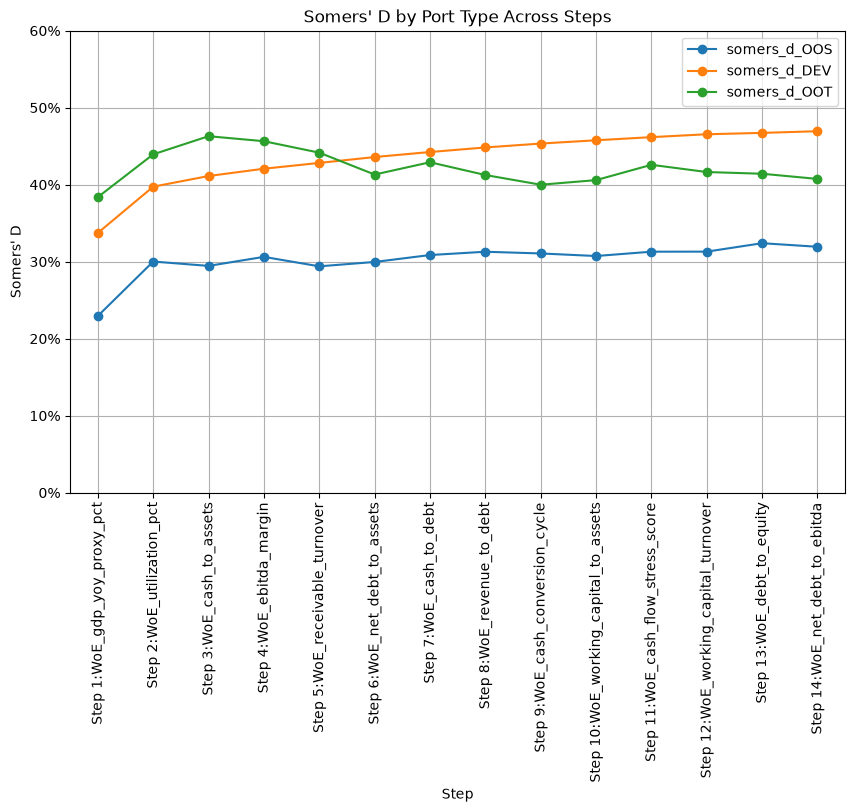

In [63]:
plt.figure(figsize=(10, 6))
for port in [col for col in step_df.columns if col.startswith("somers_d_")]:
    plt.plot(step_df.index, step_df[port], marker = 'o', label=port)
plt.ylim(0, 0.6)
plt.xlim(step_df.index.min()-0.5, step_df.index.max()+0.5)
plt.xlabel("Step")
plt.grid(True)
plt.xticks(step_df.index, labels=step_df["step + var"], rotation=90)
plt.ylabel("Somers' D")
plt.title("Somers' D by Port Type Across Steps")
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.legend(loc="best")
plt.show()

#### Overall level

In [ ]:
gini = {}

for port in tqdm(riskdiff_data_woe["port_type"].unique()):
    subset = riskdiff_data_woe[riskdiff_data_woe["port_type"] == port].copy().reset_index(drop=True)
    gini[port] = {}
    gini[port]["Observed gini"] = (2 * roc_auc_score(
        subset["default_12m"],
        subset["pd"]
    ) - 1)

    # Bootstrap to estimate the variability of the Gini coefficient
    n_bootstraps = 1000
    gini_bootstrap = []
    rng = np.random.default_rng(42)

    random_matrix = rng.choice(subset.index, size=(n_bootstraps, len(subset)), replace=True)
    for i in range(n_bootstraps):
        sample = subset.iloc[random_matrix[i]]
        gini_bootstrap.append(2 * roc_auc_score(sample["default_12m"], sample["pd"]) - 1)

    gini[port]["Bootstrap 2.5% quantile gini"] = np.percentile(gini_bootstrap, 2.5)
    gini[port]["Bootstrap 97.5% quantile gini"] = np.percentile(gini_bootstrap, 97.5)

100%|██████████| 3/3 [00:24<00:00,  8.02s/it]


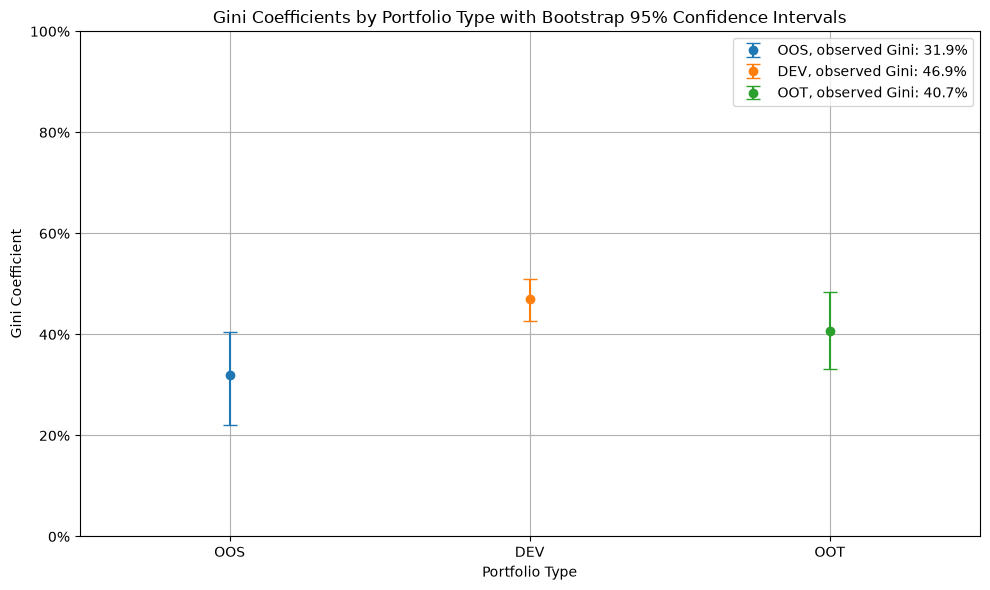

In [219]:
plt.figure(figsize=(10, 6))
for port in riskdiff_data_woe["port_type"].unique():
    plt.errorbar(
        port,
        gini[port]["Observed gini"],
        yerr=[[gini[port]["Observed gini"] - gini[port]["Bootstrap 2.5% quantile gini"]],
              [gini[port]["Bootstrap 97.5% quantile gini"] - gini[port]["Observed gini"]]],
        fmt='o',
        capsize=5,
        label=f"{port}, observed Gini: {100*gini[port]['Observed gini']:.1f}%"
    )
    
plt.ylim(0, 1)
plt.xlim(-0.5, len(riskdiff_data_woe["port_type"].unique()) - 0.5)
plt.xlabel("Portfolio Type")
plt.ylabel("Gini Coefficient")
plt.grid(True)
plt.title("Gini Coefficients by Portfolio Type with Bootstrap 95% Confidence Intervals")
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.legend(loc='best')
plt.tight_layout()
plt.show()

### Precision

In [207]:
def binom_conf_interval(n_success, n_trials, alpha=0.05):
    lower = binom.ppf(alpha / 2, n_trials, n_success / n_trials) / n_trials
    upper = binom.ppf(1 - alpha / 2, n_trials, n_success / n_trials) / n_trials
    return lower, upper

def series_lower(series):
    n_success = series.sum()
    n_trials = series.count()
    lower, _ = binom_conf_interval(n_success, n_trials)
    return lower

def series_upper(series):
    n_success = series.sum()
    n_trials = series.count()
    _, upper = binom_conf_interval(n_success, n_trials)
    return upper

precision_df = riskdiff_data_woe.groupby("port_type").agg({"default_12m": ["mean", series_lower, series_upper], "pd": "mean"})

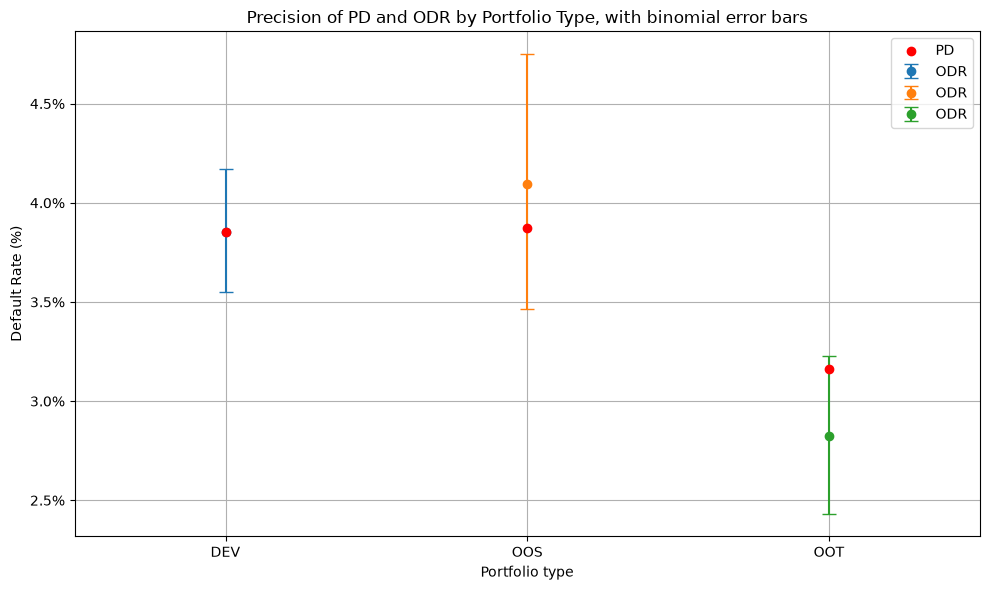

In [237]:
plt.figure(figsize=(10, 6))
for index in precision_df.index:
    subset = precision_df.loc[index]
    plt.errorbar(
        x=index,
        y=subset[("default_12m", "mean")],
        yerr=[[subset[("default_12m", "mean")] - subset[("default_12m", "series_lower")]],
              [subset[("default_12m", "series_upper")] - subset[("default_12m", "mean")]]],
        fmt='o',
        capsize=5,
        label='ODR'
    )
plt.scatter(
            x=precision_df.index,
            y=precision_df[("pd", "mean")],
            color='red',
            label='PD',
            zorder=4
        )
plt.grid(True)
plt.xlabel("Portfolio type")
plt.ylabel("Default Rate (%)")
plt.title("Precision of PD and ODR by Portfolio Type, with binomial error bars")
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
plt.xlim(left=-0.5, right=len(precision_df.index) - 0.5)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

## Saving the model

In [238]:
with open("Pickle/model.pkl", "wb") as f:
    pickle.dump(model, f)